# Hypothesis 2: Public holidays (other than Kiel Week) influence daily sales

**Purpose.** This notebook tests hypothesis 2 from the canvas (block 2): *public holidays, apart from Kiel Week, influence daily bakery sales.*

"Influence" can mean two things, and we test both:

- **A. Closure.** Is the shop closed on public holidays? Then there are no sales at all.
- **B. Level on open holidays.** On holidays when the shop is open, is turnover higher or lower than on comparable normal days?

We also take a short look at **C. the day before a holiday on which the shop is closed** (do people stock up?).

**Data rules** (from `DECISIONS.md`): public holidays come from the `holidays` package (`Germany(subdiv="SH")`); 2014-05-05 is removed; days without sales rows count as "not on offer", not as 0.

**Assumptions to confirm as a team:** we use the whole sales period (Jul 2013 – Jul 2018), and normal days within ±4 weeks of the holiday serve as the comparison.

In [1]:
import numpy as np
import pandas as pd
import holidays
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes", 6: "Seasonal bread"}
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]  # Monday to Sunday
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
print("holidays package version:", holidays.__version__)

holidays package version: 0.109


## Step 1: Load the data and build a calendar

We load the sales and the Kiel Week file and remove 2014-05-05 (decision log: probably 3 days booked together).

Then we build a **calendar**, one row per date in the sales period, including dates *without* sales. That matters here: a holiday on which the shop was closed has no sales row, so we would never see it if we only looked at the sales file.

In [2]:
sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
kiwo = pd.read_csv(BASE_URL + "kiwo.csv", parse_dates=["Datum"])
sales = sales[sales["Datum"] != "2014-05-05"]

sh_holidays = holidays.Germany(subdiv="SH", years=range(2013, 2019))

cal = pd.DataFrame({"Datum": pd.date_range("2013-07-01", "2018-07-31")})
cal["holiday"] = cal["Datum"].map(lambda d: sh_holidays.get(d))   # holiday name, or None
cal["is_holiday"] = cal["holiday"].notna()
cal["kiwo"] = cal["Datum"].isin(kiwo["Datum"])
cal["total"] = cal["Datum"].map(sales.groupby("Datum")["Umsatz"].sum())  # daily turnover, all groups
cal["open"] = cal["total"].notna()
cal["weekday"] = pd.Categorical(cal["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)

print("Days in calendar:", len(cal), "| days with sales:", cal["open"].sum())
print("Public holidays in the period:", cal["is_holiday"].sum())
print("Holidays that fall in Kiel Week:", (cal["is_holiday"] & cal["kiwo"]).sum())

Days in calendar: 1857 | days with sales: 1818
Public holidays in the period: 46
Holidays that fall in Kiel Week: 0


**What to check:** no public holiday falls in Kiel Week, so "other than Kiel Week" happens by itself. To be safe we still keep Kiel Week days out of the comparison days below.

## Step 2 (effect A): Is the shop open on public holidays?

In [3]:
hol = cal[cal["is_holiday"]]
open_table = (hol.groupby("holiday")["open"].agg(open_days="sum", holidays="count")
                 .sort_values("open_days"))
open_table

,open_days,holidays
holiday,,
Erster Weihnachtstag,0,5
Karfreitag,0,5
Neujahr,0,5
Reformationstag,0,1
Zweiter Weihnachtstag,0,5
Erster Mai,1,5
Pfingstmontag,4,5
Christi Himmelfahrt,5,5
Ostermontag,5,5


In [4]:
closed_other = cal[~cal["open"] & ~cal["is_holiday"]]
print(f"Holidays closed: {(~hol['open']).sum()} of {len(hol)}")
print(f"Non-holiday days closed: {len(closed_other)} of {(~cal['is_holiday']).sum()}")

Holidays closed: 26 of 46
Non-holiday days closed: 13 of 1811


**Result A.** The shop is closed on **26 of 46** public holidays: always on Christmas (25./26.12.), New Year, Good Friday and Reformation Day, and on 4 of 5 Labour Days (1 May). It is open on Easter Monday, Ascension Day, German Unity Day and (4 of 5) Whit Monday. On normal days a closure is rare (13 of about 1,800 days, including 2014-05-05).

So the largest "influence" is a **closure**. But it isn't a sales level that we need to forecast: the manager knows in advance when the shop is closed. For the forecast, the interesting question is B.

## Step 3 (effect B): Open holidays vs. comparable normal days

**Why not just compare averages?** Sales depend strongly on the **weekday** (Saturdays and Sundays are different) and on the **season** (summer vs. winter). Most open holidays fall on a Monday or Thursday, in spring. A plain "holiday vs. all other days" average would mix these effects together.

**Concept: a matched comparison.** For each open holiday we pick its own reference days: **the same weekday in the 4 weeks before and after** it. They have to be *normal* days: open, not a holiday, not Kiel Week, not 24.12. or 31.12. Then we compute

> ratio = holiday turnover ÷ mean turnover of its reference days

A ratio of 1.40 means "40% more than a normal day of that weekday". Because holidays may behave like Sundays (many people are off work), we repeat the comparison with the **nearby Sundays** as the reference days.

In [5]:
special = (cal["Datum"].dt.month == 12) & cal["Datum"].dt.day.isin([24, 31])
cal["normal"] = cal["open"] & ~cal["is_holiday"] & ~cal["kiwo"] & ~special

def reference_mean(date, weekday, values, weeks=4):
    """Mean of `values` on normal days with the given weekday within ±`weeks` weeks of `date`."""
    near = (cal["Datum"] - date).abs() <= pd.Timedelta(weeks=weeks)
    mask = near & cal["normal"] & (cal["weekday"] == weekday) & (cal["Datum"] != date)
    v = values[mask.values]
    return v.mean(), v.notna().sum()

open_hol = cal[cal["is_holiday"] & cal["open"]]
total = cal["total"].values
rows = []
for _, h in open_hol.iterrows():
    same, n_same = reference_mean(h["Datum"], h["weekday"], cal["total"])
    sun, n_sun = reference_mean(h["Datum"], "Sunday", cal["total"])
    rows.append({"date": h["Datum"].date(), "holiday": h["holiday"], "weekday": h["weekday"],
                 "turnover": h["total"], "same_weekday_ref": same, "n_ref": n_same,
                 "ratio_vs_same_weekday": h["total"] / same, "sunday_ref": sun,
                 "ratio_vs_sunday": h["total"] / sun})
res = pd.DataFrame(rows)
res.round(2)

,date,holiday,weekday,turnover,same_weekday_ref,n_ref,ratio_vs_same_weekday,sunday_ref,ratio_vs_sunday
0,2013-10-03,Tag der Deutschen Einheit,Thursday,1449.99,978.60,8,1.48,1264.72,1.15
1,2014-04-21,Ostermontag,Monday,1423.52,974.66,7,1.46,1345.16,1.06
2,2014-05-29,Christi Himmelfahrt,Thursday,1592.21,1029.45,6,1.55,1382.75,1.15
3,2014-06-09,Pfingstmontag,Monday,1805.71,1052.11,7,1.72,1399.20,1.29
4,2014-10-03,Tag der Deutschen Einheit,Friday,1572.02,1176.90,8,1.34,1402.27,1.12
5,2015-04-06,Ostermontag,Monday,1431.67,843.18,8,1.70,1106.71,1.29
6,2015-05-14,Christi Himmelfahrt,Thursday,1161.93,890.41,8,1.30,1145.38,1.01
7,2015-05-25,Pfingstmontag,Monday,1453.32,912.34,7,1.59,1196.70,1.21
8,2015-10-03,Tag der Deutschen Einheit,Saturday,1101.60,1255.90,8,0.88,1142.09,0.96
9,2016-03-28,Ostermontag,Monday,1311.95,755.91,8,1.74,1095.91,1.20


**What to check:** each holiday has 6–8 reference days (`n_ref`), so the comparison isn't based on one odd day.

### Is the difference real or chance? A significance test

With only 20 open holidays we use the **Wilcoxon signed-rank test**. It asks: *if holidays made no difference, how likely would it be to see ratios this far from 1?* It works on ranks, so it needs no normal distribution and is robust to single outliers. We test the logarithm of the ratio (log ratio 0 = no difference), because +40% and −29% are equally large steps on the log scale.

The **p-value** is that probability. Below 0.05 we usually call a difference *statistically significant*. We summarise the effect size with the **geometric mean** of the ratios, the fitting average for ratios.

In [6]:
def summarise(ratios, label):
    log_r = np.log(ratios)
    p = stats.wilcoxon(log_r).pvalue
    print(f"{label}: typical ratio (geometric mean) = {np.exp(log_r.mean()):.2f}, "
          f"median = {np.median(ratios):.2f}, above 1 on {(ratios > 1).sum()} of {len(ratios)} holidays, "
          f"Wilcoxon p = {p:.1g}")

summarise(res["ratio_vs_same_weekday"], "vs. same weekday")
summarise(res["ratio_vs_sunday"], "vs. Sunday       ")

vs. same weekday: typical ratio (geometric mean) = 1.42, median = 1.43, above 1 on 19 of 20 holidays, Wilcoxon p = 4e-06
vs. Sunday       : typical ratio (geometric mean) = 1.11, median = 1.11, above 1 on 15 of 20 holidays, Wilcoxon p = 0.001


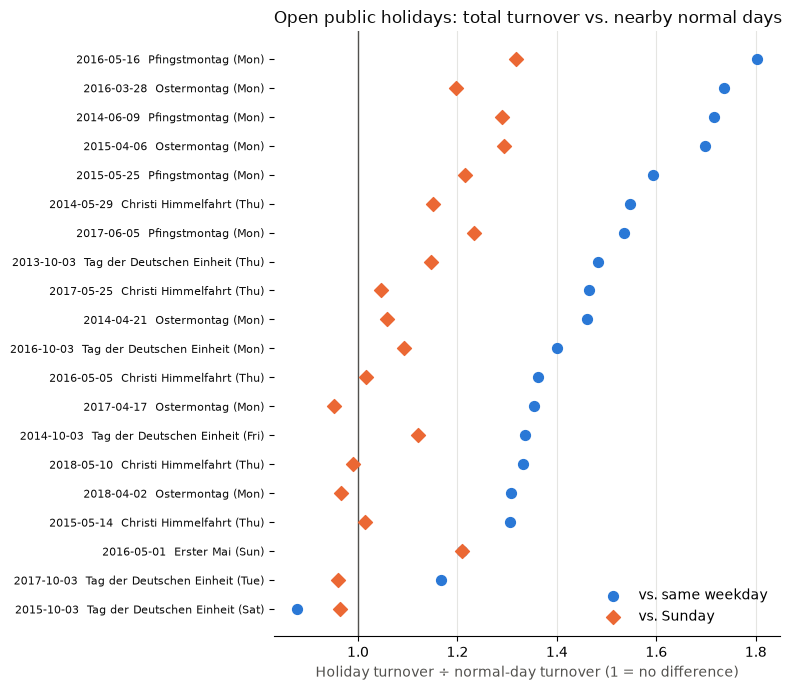

In [7]:
order = res.sort_values("ratio_vs_same_weekday")
labels = [f"{d}  {n} ({w[:3]})" for d, n, w in zip(order["date"], order["holiday"], order["weekday"])]
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 7))
ax.axvline(1, color=MUTED, lw=1)
ax.scatter(order["ratio_vs_same_weekday"], y, s=50, color=BLUE, label="vs. same weekday", zorder=3)
ax.scatter(order["ratio_vs_sunday"], y, s=50, color=ORANGE, marker="D", label="vs. Sunday", zorder=3)
ax.set_yticks(y, labels, fontsize=8, color=INK)
ax.set_xlabel("Holiday turnover ÷ normal-day turnover (1 = no difference)", color=MUTED)
ax.set_title("Open public holidays: total turnover vs. nearby normal days", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", color="#e5e5e2", lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Result B (total turnover).**
- Compared with the **same weekday**, an open holiday has about **+42%** turnover (geometric mean 1.42). It's higher on **19 of 20** holidays, p ≈ 0.000004: very unlikely to be chance.
- Compared with a **Sunday**, a holiday is still about **+11%** higher (above 1 on 15 of 20, p ≈ 0.001). A holiday is "a Sunday plus a bit".
- The only exception is **03.10.2015, a Saturday**. A holiday on a day that is already a weekend day barely changes anything.

## Step 4: Per product group

The total could hide opposite effects in the groups, so we repeat the matched comparison per product group. Seasonal bread (6) is left out: it's only on sale Oct–Jan, and so is missing for most open holidays.

In [8]:
by_group = sales.pivot_table(index="Datum", columns="Warengruppe", values="Umsatz")
group_rows = []
for g in [1, 2, 3, 4, 5]:
    values = cal["Datum"].map(by_group[g])
    r_same, r_sun = [], []
    for _, h in open_hol.iterrows():
        v = by_group[g].get(h["Datum"], np.nan)
        if pd.isna(v):
            continue
        r_same.append(v / reference_mean(h["Datum"], h["weekday"], values)[0])
        r_sun.append(v / reference_mean(h["Datum"], "Sunday", values)[0])
    ls, lsun = np.log(r_same), np.log(r_sun)
    group_rows.append({"group": GROUPS[g], "n_holidays": len(ls),
                       "vs_same_weekday": np.exp(ls.mean()), "p_same_weekday": stats.wilcoxon(ls).pvalue,
                       "vs_sunday": np.exp(lsun.mean()), "p_sunday": stats.wilcoxon(lsun).pvalue})
groups_res = pd.DataFrame(group_rows)
groups_res.round(3)

,group,n_holidays,vs_same_weekday,p_same_weekday,vs_sunday,p_sunday
0,Bread,20,0.538,0.0,0.943,0.869
1,Rolls,20,1.639,0.0,1.123,0.000
2,Croissants,20,1.695,0.0,1.138,0.005
3,Confectionery,20,1.698,0.0,1.026,0.898
4,Cakes,20,1.296,0.0,1.098,0.017


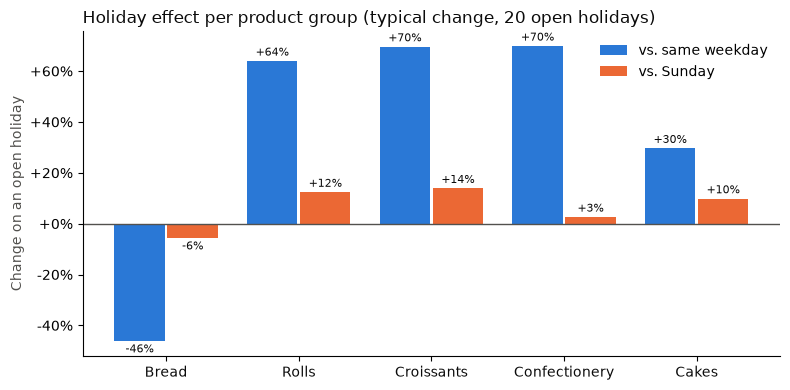

In [9]:
x = np.arange(len(groups_res)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.bar(x - w/2 - 0.01, groups_res["vs_same_weekday"] - 1, w, color=BLUE, label="vs. same weekday")
b2 = ax.bar(x + w/2 + 0.01, groups_res["vs_sunday"] - 1, w, color=ORANGE, label="vs. Sunday")
ax.bar_label(b1, labels=[f"{v:+.0%}" for v in groups_res["vs_same_weekday"] - 1], fontsize=8, color=INK, padding=2)
ax.bar_label(b2, labels=[f"{v:+.0%}" for v in groups_res["vs_sunday"] - 1], fontsize=8, color=INK, padding=2)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(x, groups_res["group"], color=INK)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_ylabel("Change on an open holiday", color=MUTED)
ax.set_title("Holiday effect per product group (typical change, 20 open holidays)", loc="left", color=INK)
ax.legend(frameon=False)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Result per group.** (A p-value shown as 0.000 means p < 0.001.) The effect is **not the same for all groups**:
- **Bread** goes *down* on holidays: about **−46%** vs. the same weekday. Compared with a Sunday there's no clear difference (p ≈ 0.87). Bread behaves like on a Sunday.
- **Rolls, croissants and confectionery** go up by **+64% to +70%** vs. the same weekday. Rolls and croissants are also clearly above a Sunday (+12–14%); confectionery is not (+3%, p ≈ 0.90), so it behaves like a Sunday.
- **Cakes**: +30% vs. the same weekday, +10% vs. Sunday.

So "holidays raise sales" is true for the total, but bread runs the other way. That's why the forecast needs the holiday effect **per product group**.

## Step 5: A second view, regression with control variables

The matched comparison controls for weekday and season by choosing reference days. A **regression** does it differently: it explains log turnover with weekday, month and year *at the same time* as a holiday yes/no variable. The holiday coefficient then says how much a holiday changes turnover **for the same weekday, month and year**. If both methods agree, we can trust the result more. (We use all open, non-Kiel-Week days, without 24.12./31.12., and robust standard errors.)

In [10]:
d = cal[cal["open"] & ~cal["kiwo"] & ~special].copy()
d["log_total"] = np.log(d["total"])
d["holiday01"] = d["is_holiday"].astype(int)
d["month"] = d["Datum"].dt.month
d["year"] = d["Datum"].dt.year
d["weekday"] = d["weekday"].astype(str)
model = smf.ols("log_total ~ holiday01 + C(weekday, Treatment('Monday')) + C(month) + C(year)", data=d).fit(cov_type="HC3")
lo, hi = np.exp(model.conf_int().loc["holiday01"])
print(f"Days used: {len(d)}")
print(f"Holiday effect: x{np.exp(model.params['holiday01']):.2f} "
      f"(95% interval x{lo:.2f} – x{hi:.2f}), p = {model.pvalues['holiday01']:.1g}")
sunday_key = "C(weekday, Treatment('Monday'))[T.Sunday]"
print(f"For comparison, Sunday vs. Monday: x{np.exp(model.params[sunday_key]):.2f}")

Days used: 1763
Holiday effect: x1.39 (95% interval x1.29 – x1.49), p = 2e-19
For comparison, Sunday vs. Monday: x1.32


**Result.** The regression gives about **+39%** for a holiday (95% interval about +29% to +49%), close to the matched comparison (+42%). Two different methods agree, which makes the result more reliable.

## Step 6 (effect C): The day before a closed holiday

If the shop is closed on a holiday, do customers buy more the day before? We compare each such day (without 24.12./31.12., which are already special inputs) with the same weekday in the ±4 weeks around it.

In [11]:
next_day = cal.shift(-1)
cal["before_closed_holiday"] = next_day["is_holiday"].fillna(False).astype(bool) & ~next_day["open"].fillna(True).astype(bool)
pre = cal[cal["before_closed_holiday"] & cal["open"] & ~special]
pre_rows = []
for i, p in pre.iterrows():
    ref, _ = reference_mean(p["Datum"], p["weekday"], cal["total"])
    pre_rows.append({"date": p["Datum"].date(), "weekday": p["weekday"],
                     "day_before": cal.loc[i + 1, "holiday"], "ratio_vs_same_weekday": p["total"] / ref})
pre_res = pd.DataFrame(pre_rows)
display(pre_res.round(2))
summarise(pre_res["ratio_vs_same_weekday"], "day before closed holiday")

,date,weekday,day_before,ratio_vs_same_weekday
0,2014-04-17,Thursday,Karfreitag,1.54
1,2014-04-30,Wednesday,Erster Mai,1.15
2,2015-04-02,Thursday,Karfreitag,1.65
3,2015-04-30,Thursday,Erster Mai,1.12
4,2017-04-13,Thursday,Karfreitag,1.86
5,2017-04-30,Sunday,Erster Mai,1.18
6,2017-10-30,Monday,Reformationstag,1.57
7,2018-03-29,Thursday,Karfreitag,1.82
8,2018-04-30,Monday,Erster Mai,1.42
9,2018-05-20,Sunday,Pfingstmontag,1.21


day before closed holiday: typical ratio (geometric mean) = 1.43, median = 1.48, above 1 on 10 of 10 holidays, Wilcoxon p = 0.002


**Result C.** The day before a closed holiday is about **+43%** above a normal day of the same weekday (all 10 days above 1, p ≈ 0.002). The strongest are the Thursdays before Good Friday (+54% to +86%). But there are **only 10 cases**, so treat the size as rough.

## Conclusion

| Question | Answer | How sure? |
|---|---|---|
| A. Closed on holidays? | Yes, on 26 of 46 (Christmas, New Year, Good Friday, mostly 1 May) | Certain (counts); known in advance |
| B. Level on open holidays (total) | About **+40%** vs. the same weekday; about +11% vs. a Sunday | Strong: 19 of 20 cases, two methods agree |
| B. Per group | Bread **−46%** (like a Sunday); rolls, croissants, confectionery **+64–70%**; cakes +30% | Clear for each group, 20 cases each |
| C. Day before a closed holiday | About **+43%** | Likely, but only 10 cases |

**Hypothesis 2 is supported:** public holidays (none of which overlap Kiel Week) clearly influence daily sales. The direction depends on the product group.

**What the data can't tell us:** only 20 open holidays (4–5 per holiday type) and 10 pre-holiday days. Effects for a single holiday type (e.g. Whit Monday) rest on 4–5 cases. Sales aren't demand: on sell-out days, true demand was higher. We tested several comparisons (total, 5 groups, two references), so a single p-value near 0.05 would deserve caution. The main results, however, have p-values far below that.

**For the model:** use "public holiday" as an input that can act differently per product group (or "holiday behaves like a Sunday" plus an extra), and add "day before a closed holiday" as an input. Closed holidays don't need forecasting.